## <img style="float: left; padding-right: 10px; width: 100px" src="https://raw.githubusercontent.com/sbildea/SEED/main/imagini/unitbv_mie.png"> <center>Știința Explorării și Exploatării Datelor - SEED1</center>

##    <center>Extra 4: Exerciții de regresie (Boston)</center>
**Universitatea Transilvania**<br>
**SIIPA, Semestrul I**<br>
**Instructor:** Conf. dr. Teodor &Scedil;tefan B&icirc;ldea<br>
**Contact:** teodor.bildea@unitbv.ro<br>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sbildea/SEED/blob/main/cursuri/04-regresie/extra-04-exercitii-regresie-boston.ipynb)

In [ ]:
# Configurare curs SEED: rulați această celulă prima.
# Colab: descarcă materialele cursului și instalează pachetele lipsă (aprox. un minut).
# Local: găsește singură rădăcina repository-ului, oricare ar fi folderul curent al kernelului.
import os, sys
MODUL = "04-regresie"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SEED"):
        !git clone -q --depth 1 https://github.com/sbildea/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    RADACINA = "/content/SEED"
else:
    RADACINA = os.path.abspath(".")
    while not os.path.isdir(os.path.join(RADACINA, "seed")) and os.path.dirname(RADACINA) != RADACINA:
        RADACINA = os.path.dirname(RADACINA)
    import importlib.util, socket
    lipsa = [p for p in ("pandas", "matplotlib", "seaborn", "sklearn") if importlib.util.find_spec(p) is None]
    if lipsa:
        print("Lipsesc pachetele", lipsa, "- în terminal: pip install -r requirements-local.txt")
    try:
        socket.create_connection(("raw.githubusercontent.com", 443), 2).close()
    except OSError:
        print("Fără internet: imaginile din text nu se văd. O singură dată, în terminal: python tools/imagini_offline.py")
os.chdir(os.path.join(RADACINA, "cursuri", MODUL))
sys.path.insert(0, RADACINA)

## Etica universitară

### Colaborare vs plagiat

Colaborarea între voi este încurajată atât timp cât nu cade în categoria plagiatului așa cum este descris în statutul studentului.

Copiatul, plagiatul și orice altă formă de incorectitudine academică nu vor fi tolerate și vor fi sancționate conform statutului studentului.

În principiu, dacă scrieți cod și vă întreb ce face o linie de cod <i>trimisă</i> de voi ca temă, mă aștept să știți să îmi explicați. 

# INSTRUCȚIUNI

- Toate exercițiile sunt obligatorii

### FORMAT NUME FIȘIER TEMĂ
- Exercițiile vor fi redactate în mediul Jupyter, într-un fișier salvat ca și 
`TEMA 1 - <nume prenume>.ipynb`
unde în loc de `<nume prenume>` veți scrie numele și prenumele vostru așa cum apar în catalog – vom evita diacriticele. 
- De exemplu: 

TEMA 5 – BILDEA TEODOR STEFAN.ipynb

<b>ATENȚIE</b> 
> Nerespectarea formatului pentru trimiterea temei va aduce cu sine depunctarea cu 1 punct (din 10).   
> Fiecare exercițiu va fi rezolvat într-o celulă separată

Nu uitați să rulați celula cu importuri:

In [6]:
from pathlib import Path

import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import OLSInfluence

from pygam import LinearGAM, s, l
from pygam.datasets import wage


import seaborn as sns
import matplotlib.pyplot as plt

from dmba import stepwise_selection
from dmba import AIC_score

# Temă de seminar:
    
Incarcati setul de date boston_housing.csv. Cele 14 coloane sunt următoarele:
1. CRIM: rata criminalității pe cap de locuitor pe oraș
2. ZN: proporție de teren rezidențial zonat pentru loturi de peste 25.000 mp.
3. INDUS: proporție de suprafata(acri) de afaceri non-retail pe oraș
4. CHAS: variabila dummy a râului Charles (= 1 dacă traiectul limitează râul; 0 altfel)
5. NOX: concentrație de oxizi azotici (părți la 10 milioane) 
6. RM: numărul mediu de camere pe locuință
7. age: proporția de unități ocupate de proprietari construite înainte de 1940
8. DIS: distanțe ponderate până la cinci centre de angajare din Boston
9. RAD: indicele de accesibilitate la autostrăzile radiale
10. IMPOZIT: impozit pe valoarea integrală \ 10.000 USD
11. PTRATIO: raport elev-profesor în funcție de oraș (numarul de profesori vs numar de elevi)
12. B: 1000 (Bk − 0,63) 2 unde Bk este proporția de afro-americani pe oraș
13. LSTAT:% populație nivel de trai scazut
14. MEDV: Valoarea medie a caselor ocupate de proprietari în mii de dolari$ 

Putem vedea că atributele de intrare au un amestec de unități

Există 450 de observații.

<div class="exercise"><b>Exercitiu</b></div>

Folosind fișierul de mai sus, in cele ce urmeaza veti încerca să preziceti cât mai bine coloana 14-MDEV, cu prețurile caselor. 

1. Încărcați datele. Formatul e csv. Uitați-vă rapid la un rezumat al datelor pentru a vă familiariza cu acestea și pentru a vă asigura că nimic nu este prea grav (date lipsă, coloane neutilizabile, etc).

2. Utilizați o funcție discutată anterior pentru a partiționa automat datele într-un set de antrenare și validare. Depindeți de dvs. să alegeți cât de mari ar trebui să fie aceste două parti. 

<b>Atenție</b> - folosiți pentru <i>random_state</i> numărul vostru de ordine din catalog!

3. Din atributele numerice alegeți-l pe cel mai bine corelat cu coloana 14 și creați un model de regresie (cel mai bine corelat -> matricea de corelație. Vedeți cursurile anterioare)

4. La sfârșit testați modelul de predicție cu datele din `boston_housing_test.csv` - încărcați și, cu modelul antrenat, apelați metoda predict, apoi cu predicții și valorile actuale y calculați MAE și MAPE.


In [7]:
# codul vostru aici
df_train = pd.read_csv('./date/boston_housing.csv')

df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     450 non-null    float64
 1   ZN       450 non-null    float64
 2   INDUS    450 non-null    float64
 3   CHAS     450 non-null    float64
 4   NOX      450 non-null    float64
 5   RM       450 non-null    float64
 6   age      450 non-null    float64
 7   DIS      450 non-null    float64
 8   RAD      450 non-null    int64  
 9   IMPOZIT  450 non-null    float64
 10  PTRATIO  450 non-null    float64
 11  B        450 non-null    float64
 12  LSTAT%   450 non-null    float64
 13  MEDV     401 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 49.3 KB


In [8]:
df_train_clean = df_train.dropna()
df_train_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 401 entries, 0 to 449
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     401 non-null    float64
 1   ZN       401 non-null    float64
 2   INDUS    401 non-null    float64
 3   CHAS     401 non-null    float64
 4   NOX      401 non-null    float64
 5   RM       401 non-null    float64
 6   age      401 non-null    float64
 7   DIS      401 non-null    float64
 8   RAD      401 non-null    int64  
 9   IMPOZIT  401 non-null    float64
 10  PTRATIO  401 non-null    float64
 11  B        401 non-null    float64
 12  LSTAT%   401 non-null    float64
 13  MEDV     401 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 47.0 KB


In [9]:
df_train_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
CRIM,401.0,1.145500,2.300286,0.00632,0.06617,0.16211,0.75026,9.96654
ZN,401.0,14.339152,25.376115,0.00000,0.00000,0.00000,21.00000,100.00000
INDUS,401.0,9.438005,6.518009,0.46000,4.15000,7.07000,13.92000,25.65000
CHAS,401.0,0.087282,0.282600,0.00000,0.00000,0.00000,0.00000,1.00000
NOX,401.0,0.530623,0.114842,0.38500,0.44200,0.50700,0.58100,0.87100
RM,401.0,6.364995,0.684559,3.56100,5.92800,6.24500,6.67400,8.78000
age,401.0,63.930923,28.809775,2.90000,37.80000,68.80000,91.60000,100.00000
DIS,401.0,4.217737,2.150512,1.12960,2.32740,3.87500,5.64840,12.12650
RAD,401.0,6.660848,6.354895,1.00000,4.00000,5.00000,6.00000,24.00000
IMPOZIT,401.0,350.568579,129.211419,187.00000,276.00000,307.00000,403.00000,666.00000


In [10]:
from sklearn.model_selection import train_test_split

traindf, testdf = train_test_split(df_train_clean, test_size=0.2, random_state=42)

In [11]:
df_tmp = traindf.corr()[['MEDV']].sort_values(by = 'MEDV',ascending=False)

df_tmp['abs_corr'] = df_tmp['MEDV'].abs()
df_tmp= df_tmp.sort_values(by='abs_corr', ascending=False)
df_tmp

,MEDV,abs_corr
MEDV,1.000000,1.000000
RM,0.753491,0.753491
LSTAT%,-0.699689,0.699689
PTRATIO,-0.433768,0.433768
INDUS,-0.340677,0.340677
ZN,0.334245,0.334245
NOX,-0.277879,0.277879
IMPOZIT,-0.271439,0.271439
CRIM,-0.250345,0.250345
age,-0.237672,0.237672


In [12]:
df_train_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
CRIM,401.0,1.145500,2.300286,0.00632,0.06617,0.16211,0.75026,9.96654
ZN,401.0,14.339152,25.376115,0.00000,0.00000,0.00000,21.00000,100.00000
INDUS,401.0,9.438005,6.518009,0.46000,4.15000,7.07000,13.92000,25.65000
CHAS,401.0,0.087282,0.282600,0.00000,0.00000,0.00000,0.00000,1.00000
NOX,401.0,0.530623,0.114842,0.38500,0.44200,0.50700,0.58100,0.87100
RM,401.0,6.364995,0.684559,3.56100,5.92800,6.24500,6.67400,8.78000
age,401.0,63.930923,28.809775,2.90000,37.80000,68.80000,91.60000,100.00000
DIS,401.0,4.217737,2.150512,1.12960,2.32740,3.87500,5.64840,12.12650
RAD,401.0,6.660848,6.354895,1.00000,4.00000,5.00000,6.00000,24.00000
IMPOZIT,401.0,350.568579,129.211419,187.00000,276.00000,307.00000,403.00000,666.00000


In [ ]:
from sklearn.metrics import mean_absolute_error as MAE
from sklearn.metrics import mean_absolute_percentage_error  as MAPE
import matplotlib.pyplot as plt

model = LinearRegression()

results = []
for predictor in [c for c in traindf.columns if c != 'MEDV']:
    model.fit(X = traindf[[predictor]], y = traindf['MEDV'] )
    y_hat_train = model.predict(X = traindf[[predictor]])
    y_pred = model.predict(X = testdf[[predictor]])
    error = r2_score(traindf['MEDV'], y_hat_train)
    err_mae = MAE(testdf['MEDV'], y_pred)
    err_MAPE = round(100*MAPE(testdf['MEDV'], y_pred),2)
    results.append(
        {'Predictor': predictor,
           'R2': round(error,3), 
           'MAE': round(err_mae,3),
            'MAPE': round(err_MAPE,3 )
        }
    )
    # plt.scatter(testdf['MEDV'],y_pred
    #             # title = f'Predictor: {predictor}'
    #         )
    # plt.scatter(testdf[predictor], y_pred, label='Predicted')
    # plt.title(f'Predictor: {predictor} - R2: {error:0.3f}, MAE: {err_mae:0.3f}, MAPE: {err_MAPE:0.3f}')
    # plt.show()
individual_pred_power = pd.DataFrame(results).sort_values(by='MAE', ascending=True)
individual_pred_power

,Predictor,R2,MAE,MAPE
5,RM,0.568,4.246,21.79
12,LSTAT%,0.490,5.109,21.32
10,PTRATIO,0.188,6.193,26.13
2,INDUS,0.116,6.204,26.86
9,IMPOZIT,0.074,6.407,27.68
0,CRIM,0.063,6.522,27.52
4,NOX,0.077,6.591,28.81
6,age,0.056,6.613,28.82
1,ZN,0.112,6.641,29.01
11,B,0.055,6.745,29.33


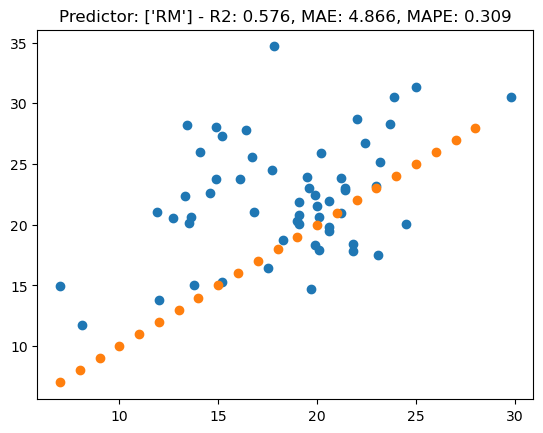

In [27]:
predictors = ['RM']
model.fit(X = df_train_clean[predictors], 
                        y = df_train_clean['MEDV'] )

y_pred = model.predict(X = df_train_clean[predictors])
error = r2_score(df_train_clean['MEDV'], y_pred)

df_test= pd.read_csv('./date/boston_housing_test.csv')
y_pred = model.predict(X = df_test[predictors]) 
err_mae = MAE(df_test['MEDV'], y_pred)
err_MAPE = MAPE(df_test['MEDV'], y_pred)

plt.scatter(df_test['MEDV'],y_pred)
plt.scatter([x for x in range(int(df_test['MEDV'].min()), int(df_test['MEDV'].max()))],
            [x for x in range(int(df_test['MEDV'].min()), int(df_test['MEDV'].max()))])
plt.title(f'Predictor: {predictors} - R2: {error:0.3f}, MAE: {err_mae:0.3f}, MAPE: {err_MAPE:0.3f}')
plt.show()

# Importanta fiecaruia intr-un model plin

In [30]:

# Importanta fiecaruia intr-un model plin

from sklearn.metrics import mean_absolute_error as MAE
from sklearn.metrics import mean_absolute_percentage_error  as MAPE
import matplotlib.pyplot as plt

model = LinearRegression()

results = []
for predictor in [c for c in traindf.columns if c != 'MEDV']:

    # model 'plin' din care scoate un predictor
    predictors = [c for c in traindf.columns if c != 'MEDV' and c != predictor]
    model.fit(X = traindf[predictors], 
                           y = traindf['MEDV'] )
    
    y_pred = model.predict(X = testdf[predictors])
    error = r2_score(traindf['MEDV'], model.predict(X = traindf[predictors]))
    err_mae = MAE(testdf['MEDV'], y_pred)
    err_MAPE = MAPE(testdf['MEDV'], y_pred)
    results.append(
        {'Predictor scos': predictor,
           'R2': round(error,3), 
           'MAE': round(err_mae,3),
            'MAPE': round(err_MAPE,3 )
        }
    )
    # plt.scatter(testdf['MEDV'],y_pred
    #             # title = f'Predictor: {predictor}'
    #         )
    # plt.scatter(testdf[predictor], y_pred, label='Predicted')
    # plt.title(f'Predictor: {predictor} - R2: {error:0.3f}, MAE: {err_mae:0.3f}, MAPE: {err_MAPE:0.3f}')
    # plt.show()
back_drop = pd.DataFrame(results).sort_values(by='MAE', ascending=False)


back_drop


,Predictor scos,R2,MAE,MAPE
5,RM,0.685,4.314,0.175
10,PTRATIO,0.717,3.613,0.161
9,IMPOZIT,0.736,3.503,0.153
8,RAD,0.735,3.502,0.152
11,B,0.737,3.474,0.155
0,CRIM,0.742,3.445,0.151
3,CHAS,0.738,3.437,0.152
1,ZN,0.734,3.429,0.154
7,DIS,0.717,3.427,0.155
6,age,0.742,3.418,0.149


In [31]:
df_tmp = individual_pred_power.merge(
    back_drop,
    left_on = 'Predictor',
    right_on = 'Predictor scos',
)
df_tmp

,Predictor,R2_x,MAE_x,MAPE_x,Predictor scos,R2_y,MAE_y,MAPE_y
0,RM,0.568,4.246,21.79,RM,0.685,4.314,0.175
1,LSTAT%,0.490,5.109,21.32,LSTAT%,0.677,3.355,0.152
2,PTRATIO,0.188,6.193,26.13,PTRATIO,0.717,3.613,0.161
3,INDUS,0.116,6.204,26.86,INDUS,0.741,3.409,0.150
4,IMPOZIT,0.074,6.407,27.68,IMPOZIT,0.736,3.503,0.153
5,CRIM,0.063,6.522,27.52,CRIM,0.742,3.445,0.151
6,NOX,0.077,6.591,28.81,NOX,0.736,3.313,0.145
7,age,0.056,6.613,28.82,age,0.742,3.418,0.149
8,ZN,0.112,6.641,29.01,ZN,0.734,3.429,0.154
9,B,0.055,6.745,29.33,B,0.737,3.474,0.155


In [34]:
import plotly.express as px
fig = px.scatter(
    # pe Ox: predictor important solo cand MAE_x e mic (eroare mica, importanta mare)
    x = 1/df_tmp['MAPE_x'], # ca scala importantei sa fie la fel ca pe y 
    y = df_tmp['MAPE_y'], # importanta mare daca eroarea MAE_y e mare (cand scote predictorul din model)
    text = df_tmp['Predictor'],

)
fig.update_traces(textposition='top center')
fig.update_xaxes(title_text='Importanta individuala (1/MAE)')
fig.update_yaxes(title_text='Importanta in modelul complet (MAE cand se scoate predictorul)')
fig.show()

In [39]:
predictors = ['RM','PTRATIO','LSTAT%','IMPOZIT','CRIM','INDUS','age','B','ZN',
              'RAD','NOX','CHAS','DIS']

results =[]
for i in range(1, len(predictors)+1):
    model.fit(X = traindf[predictors[:i]], 
                            y = traindf['MEDV'] )
        
    y_pred = model.predict(X = testdf[predictors[:i]])
    error = r2_score(traindf['MEDV'], model.predict(X = traindf[predictors[:i]]))
    err_mae = MAE(testdf['MEDV'], y_pred)
    err_MAPE = MAPE(testdf['MEDV'], y_pred)

    results.append(
        {
            'i': i,
            'Predictors': predictors[:i],
            'R2': round(error,3), 
            'MAE': round(err_mae,3),
            'MAPE': round(err_MAPE,3 )
        }
    )
df = pd.DataFrame(results)
df

,i,Predictors,R2,MAE,MAPE
0,1,[RM],0.568,4.246,0.218
1,2,"[RM, PTRATIO]",0.597,3.744,0.185
2,3,"[RM, PTRATIO, LSTAT%]",0.682,3.586,0.162
3,4,"[RM, PTRATIO, LSTAT%, IMPOZIT]",0.682,3.619,0.165
4,5,"[RM, PTRATIO, LSTAT%, IMPOZIT, CRIM]",0.687,3.673,0.173
5,6,"[RM, PTRATIO, LSTAT%, IMPOZIT, CRIM, INDUS]",0.691,3.612,0.168
6,7,"[RM, PTRATIO, LSTAT%, IMPOZIT, CRIM, INDUS, age]",0.695,3.583,0.167
7,8,"[RM, PTRATIO, LSTAT%, IMPOZIT, CRIM, INDUS, ag...",0.702,3.503,0.160
8,9,"[RM, PTRATIO, LSTAT%, IMPOZIT, CRIM, INDUS, ag...",0.702,3.519,0.160
9,10,"[RM, PTRATIO, LSTAT%, IMPOZIT, CRIM, INDUS, ag...",0.712,3.435,0.157


In [16]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56 entries, 0 to 55
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     56 non-null     float64
 1   ZN       56 non-null     int64  
 2   INDUS    56 non-null     float64
 3   CHAS     56 non-null     int64  
 4   NOX      56 non-null     float64
 5   RM       56 non-null     float64
 6   age      56 non-null     float64
 7   DIS      56 non-null     float64
 8   RAD      56 non-null     int64  
 9   IMPOZIT  56 non-null     int64  
 10  PTRATIO  56 non-null     float64
 11  B        56 non-null     float64
 12  LSTAT%   56 non-null     float64
 13  MEDV     56 non-null     float64
dtypes: float64(10), int64(4)
memory usage: 6.2 KB


# Pentru Tema 5 cu regresie multiliniara

In [ ]:
df_train_clean.columns

traindf, testdf = train_test_split(df_train_clean, test_size=0.2, random_state=42)

Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'age', 'DIS', 'RAD',
       'IMPOZIT', 'PTRATIO', 'B', 'LSTAT%', 'MEDV'],
      dtype='object')

<Axes: >

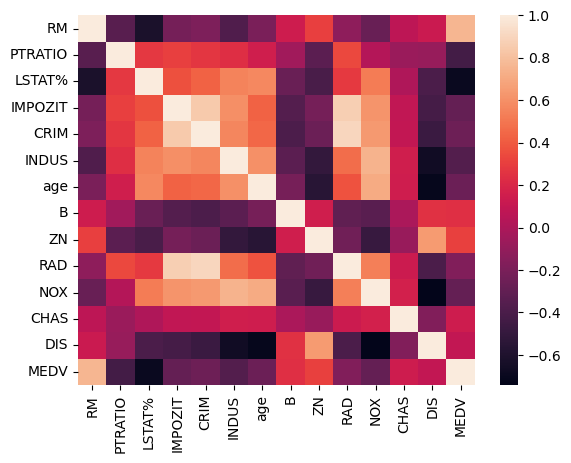

In [47]:
import seaborn as sns
# model cu predictori selectati manual
predictors = ['RM','PTRATIO','LSTAT%','IMPOZIT','CRIM','INDUS','age','B','ZN', 'RAD','NOX','CHAS','DIS']
df_train_clean[predictors + ['MEDV'] ].corr()
sns.heatmap(df_train_clean[predictors + ['MEDV'] ].corr())

In [49]:
# scalare date test

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()


In [51]:
results =[]

# 1,model cu predictori adaugati manual
predictori_alesi_manual = ['RM','PTRATIO'] # AICI ALEGETI VOI CEI MAI BUNI PREDICTORI MANUAL
X_train_manual = scaler.fit_transform(traindf[predictori_alesi_manual])
X_test_manual = scaler.fit_transform(testdf[predictori_alesi_manual])
model.fit(X = X_train_manual,  y = traindf['MEDV'] )
    
y_pred = model.predict(X = X_test_manual)
error = r2_score(traindf['MEDV'], model.predict(X = X_train_manual))
err_mae = MAE(testdf['MEDV'], y_pred)
err_MAPE = MAPE(testdf['MEDV'], y_pred)

results.append(
    {
        'tip model': 'manual',
        'Predictors': predictors,
        'R2': round(error,3), 
        'MAE': round(err_mae,3),
        'MAPE': round(err_MAPE,3 )
    }
)
results

[{'tip model': 'manual',
  'Predictors': ['RM',
   'PTRATIO',
   'LSTAT%',
   'IMPOZIT',
   'CRIM',
   'INDUS',
   'age',
   'B',
   'ZN',
   'RAD',
   'NOX',
   'CHAS',
   'DIS'],
  'R2': 0.597,
  'MAE': 3.729,
  'MAPE': 0.183}]

In [56]:
# 2,model Lasso
from sklearn.linear_model import LassoCV, Lasso
nr_catalog = 10

X_train = scaler.fit_transform(traindf[predictors])
X_test = scaler.fit_transform(testdf[predictors])
model = LassoCV(cv=5, random_state=nr_catalog)

model.fit(X = traindf[predictors], 
                        y = traindf['MEDV'] )
    
y_pred = model.predict(X = testdf[predictors])


lambda_values = 10**np.linspace(5,-5,100) # [0.0001,0.01,0.1,1,10,100,1000]
# normalize = True pentru ca toti predictorii sa fie normalizati la aceeiasi scala
lassocv_scalat2 = LassoCV(
        alphas = lambda_values, 
        cv = 10, 
        max_iter = 100000, 
        n_jobs = 10)

lassocv_scalat2.fit(X_train, traindf['MEDV'])

#pas 5
lambda_optim_scalat2 = lassocv_scalat2.alpha_

# pas 6: reantrenare pe toate datele de antrenament
lasso_scalat2 = Lasso(max_iter = 100000)#, normalize = True)
lasso_scalat2.set_params(alpha=lambda_optim_scalat2)
lasso_scalat2.fit(X_train, traindf['MEDV'])


# pas 7 - raportarea erorii
y_hat_lasso_fit2 =  lasso_scalat2.predict(X_train)
y_hat_lasso_test2 = lasso_scalat2.predict(X_test)
error = r2_score(traindf['MEDV'], y_hat_lasso_fit2)
err_mae = MAE(testdf['MEDV'], y_hat_lasso_test2)
err_MAPE = MAPE(testdf['MEDV'], y_hat_lasso_test2)

results.append(
    {
        'tip model': 'LASSO',
        'Predictors': predictors,
        'R2': round(error,3), 
        'MAE': round(err_mae,3),
        'MAPE': round(err_MAPE,3),
        'reg_param': lambda_optim_scalat2 
    }
)
results_df = pd.DataFrame(results)
results_df

,tip model,Predictors,R2,MAE,MAPE,reg_param
0,manual,"[RM, PTRATIO, LSTAT%, IMPOZIT, CRIM, INDUS, ag...",0.597,3.729,0.183,NaN
1,LASSO,"[RM, PTRATIO, LSTAT%, IMPOZIT, CRIM, INDUS, ag...",0.738,3.443,0.151,NaN
2,LASSO,"[RM, PTRATIO, LSTAT%, IMPOZIT, CRIM, INDUS, ag...",0.738,3.443,0.151,NaN
3,LASSO,"[RM, PTRATIO, LSTAT%, IMPOZIT, CRIM, INDUS, ag...",0.738,3.443,0.151,0.086975
